# Classificação Zero-Shot sob Mudança de Domínio: Prompt Único vs. Prompt Ensembling no CLIP ViT-B/32

**Disciplina:** Inteligência Artificial, CESAR School

Este notebook implementa o estudo comparativo descrito em `relatorio_ieee.tex`. Três técnicas compõem o pipeline:

| Técnica | Papel no experimento |
|---|---|
| **A. Vision Transformer ViT-B/32** | Backbone visual do CLIP: a imagem 224×224 é dividida em 7×7 = 49 patches de 32×32, mais o token `[CLS]`, cuja saída é projetada no espaço latente compartilhado. |
| **B. CLIP** (`openai/clip-vit-base-patch32`) | Alinhamento multimodal contrastivo: imagem e texto são projetados em um espaço de 512 dimensões e comparados por similaridade de cosseno. |
| **C. Estratégia de inferência textual** | Variável experimental: prompt único (H0) contra média L2-normalizada de 8 templates (H1). |

**Hipóteses** (métrica primária: acurácia Top-1, diferença pareada $\Delta_i = \text{Acc}^{H1}_i - \text{Acc}^{H0}_i$):

- $H_0$: $\mu_\Delta = 0$, isto é, o Prompt Ensembling não altera a acurácia zero-shot sob mudança de domínio.
- $H_1$: $\mu_\Delta \neq 0$, isto é, a estratégia de inferência textual altera a acurácia.

**Protocolo:** 30 simulações (sementes 1 a 30). Em cada rodada, 500 imagens (5 por classe) são amostradas de forma estratificada do conjunto de teste do CIFAR-100 com shift de domínio aplicado, e os dois cenários são avaliados exatamente sobre as mesmas imagens.

In [1]:
import os

os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

import platform

import numpy as np
import pandas as pd
import torch
import transformers
from IPython.display import Image, display

from zeroshot import config
from zeroshot.data import load_shifted_cifar100
from zeroshot.experiment import run_simulations
from zeroshot.model import ZeroShotCLIP, get_device
from zeroshot.plots import (fig_accuracy_box, fig_metric_bars, fig_paired_evolution,
                            fig_shift_examples, set_style)
from zeroshot.stats import save_summary, summarize

config.RESULTS_DIR.mkdir(exist_ok=True)
config.FIGURES_DIR.mkdir(exist_ok=True)
set_style()
transformers.utils.logging.disable_progress_bar()
pd.set_option("display.float_format", "{:.4f}".format)

device = get_device()
print(f"Dispositivo: {device} | torch {torch.__version__} | transformers {transformers.__version__} | Python {platform.python_version()}")
print(f"CPU: {platform.processor()} | threads: {torch.get_num_threads()}")

C:\Users\Silvio Fittipaldi\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: cpu | torch 2.12.0+cpu | transformers 5.8.1 | Python 3.13.0
CPU: Intel64 Family 6 Model 183 Stepping 1, GenuineIntel | threads: 14


## 1. Dataset e mudança de domínio controlada

O conjunto de teste do CIFAR-100 (10.000 imagens, 100 classes) é baixado via `torchvision.datasets`. Cada imagem recebe, de forma fixa e balanceada dentro de cada classe (semente 0), um de quatro tipos de shift aplicados na resolução nativa de 32×32:

1. **Ruído gaussiano** aditivo ($\sigma = 0{,}08$), com gerador semeado pelo índice da imagem.
2. **Desfoque gaussiano** (kernel 5×5, $\sigma = 0{,}7$).
3. **Escala de cinza com baixo contraste** (fator de contraste 0,4).
4. **Esboço sintético**: magnitude do gradiente de Sobel invertida, gerando traços escuros sobre fundo branco.

Como o shift depende apenas do índice da imagem, uma mesma imagem é sempre idêntica em qualquer rodada e em qualquer cenário.

Imagens: 10000 | classes: 100
Distribuição dos shifts: {'ruido_gaussiano': 2500, 'desfoque_gaussiano': 2500, 'cinza_baixo_contraste': 2500, 'esboco': 2500}


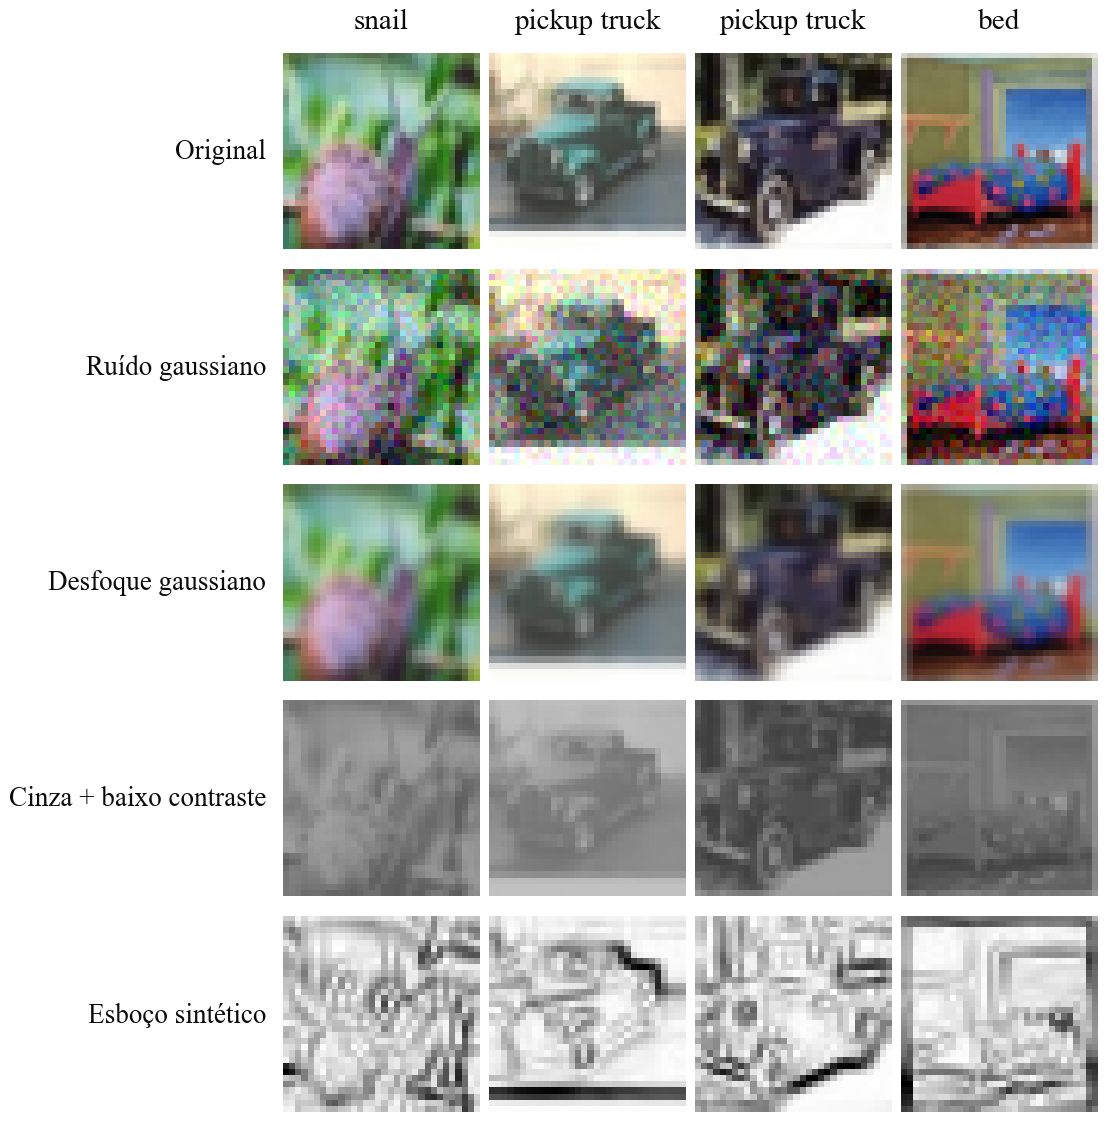

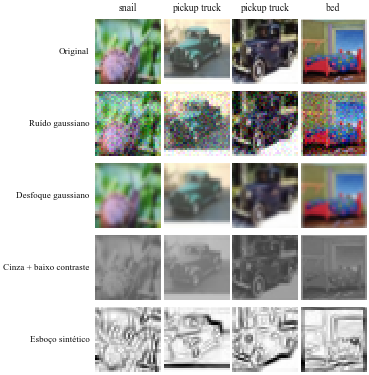

In [2]:
data = load_shifted_cifar100()
print(f"Imagens: {len(data.labels)} | classes: {len(data.classnames)}")
print("Distribuição dos shifts:", dict(zip(config.SHIFTS, np.bincount(data.shifts).tolist())))
display(Image(filename=fig_shift_examples(data, config.FIGURES_DIR / "fig0_exemplos_shift.png"), width=420))

## 2. Modelo: CLIP com backbone ViT-B/32

Os pesos pré-treinados são carregados do Hugging Face. O tokenizador BPE é lido diretamente do `tokenizer.json` oficial do repositório do modelo.

In [3]:
clip = ZeroShotCLIP(device=device)
vision = clip.model.config.vision_config
n_patches = (vision.image_size // vision.patch_size) ** 2
n_params = sum(p.numel() for p in clip.model.parameters())
print(f"Patches por imagem: {n_patches} ({vision.patch_size}x{vision.patch_size}) + 1 token [CLS] = {n_patches + 1} tokens")
print(f"Camadas do ViT: {vision.num_hidden_layers} | dimensão oculta: {vision.hidden_size} | espaço conjunto: {clip.model.config.projection_dim}")
print(f"Parâmetros totais: {n_params / 1e6:.1f} M | escala de logit aprendida: {clip.model.logit_scale.exp().item():.1f}")

Patches por imagem: 49 (32x32) + 1 token [CLS] = 50 tokens
Camadas do ViT: 12 | dimensão oculta: 768 | espaço conjunto: 512
Parâmetros totais: 151.3 M | escala de logit aprendida: 100.0


## 3. Estratégias de inferência textual (Técnica C)

Para cada classe $c$ e template $t$, o embedding textual normalizado é $\mathbf{w}_{c,t} = g(t(c)) / \lVert g(t(c)) \rVert_2$. O classificador do Prompt Ensembling é

$$\mathbf{w}_c = \frac{\frac{1}{T}\sum_{t=1}^{T} \mathbf{w}_{c,t}}{\left\lVert \frac{1}{T}\sum_{t=1}^{T} \mathbf{w}_{c,t} \right\rVert_2},$$

e a predição é $\hat{y} = \arg\max_c \; \tau \cdot \cos(\mathbf{v}, \mathbf{w}_c)$, com $\mathbf{v}$ o embedding da imagem. H0 corresponde a $T = 1$.

In [4]:
for scenario in config.SCENARIOS:
    print(f"{config.SCENARIO_LABELS[scenario]} ({len(config.TEMPLATES[scenario])} template(s)):")
    for template in config.TEMPLATES[scenario]:
        print(f"    {template.format('{classe}')}")

classifiers = {s: clip.build_classifier(data.classnames, config.TEMPLATES[s]) for s in config.SCENARIOS}
cosine = (classifiers["H0"] * classifiers["H1"]).sum(dim=-1)
print(f"\nSimilaridade de cosseno entre os protótipos H0 e H1 por classe: média {cosine.mean():.3f}, mínimo {cosine.min():.3f}")

H0: prompt único (1 template(s)):
    a photo of a {classe}.
H1: prompt ensembling (8 template(s)):
    a photo of a {classe}.
    a blurry photo of a {classe}.
    a sketch of a {classe}.
    a low contrast photo of a {classe}.
    a cropped photo of a {classe}.
    a bright photo of a {classe}.
    a dark photo of a {classe}.
    a painting of a {classe}.



Similaridade de cosseno entre os protótipos H0 e H1 por classe: média 0.980, mínimo 0.973


## 4. Execução das 30 simulações pareadas

Em cada rodada a ordem de execução dos cenários é alternada (H0 primeiro nas sementes ímpares, H1 primeiro nas pares) para evitar viés sistemático de cache nas medidas de tempo. São registrados:

- **Acurácia Top-1** e **F1-Score Macro** (100 classes);
- **Tempo médio de inferência por imagem** (codificação visual + similaridade + argmax, em ms);
- **Tempo de construção do classificador textual** (codificação dos prompts, em s);
- Acurácia por tipo de shift.

In [5]:
results = run_simulations(clip, data, n=config.N_SIMULATIONS)
results.to_csv(config.RESULTS_DIR / "simulacoes_30_rodadas.csv", index=False)
print(f"{len(results)} linhas salvas em resultados/simulacoes_30_rodadas.csv")
results.head(10)

Simulações:   0%|          | 0/30 [00:00<?, ?it/s]

Simulações:   3%|▎         | 1/30 [00:22<10:58, 22.71s/it]

Simulações:   7%|▋         | 2/30 [00:46<11:00, 23.60s/it]

Simulações:  10%|█         | 3/30 [01:14<11:25, 25.39s/it]

Simulações:  13%|█▎        | 4/30 [01:43<11:33, 26.68s/it]

Simulações:  17%|█▋        | 5/30 [02:11<11:26, 27.47s/it]

... (24 outputs left out)

Simulações: 100%|██████████| 30/30 [13:24<00:00, 26.34s/it]

Simulações: 100%|██████████| 30/30 [13:24<00:00, 26.83s/it]

60 linhas salvas em resultados/simulacoes_30_rodadas.csv


,seed,cenario,n_imagens,n_templates,acuracia_top1,f1_macro,tempo_inferencia_ms_img,tempo_classificador_s,acuracia_ruido_gaussiano,acuracia_desfoque_gaussiano,acuracia_cinza_baixo_contraste,acuracia_esboco
0,1,H0,500,1,0.2440,0.2428,20.1758,0.2189,0.1894,0.4016,0.2672,0.1000
1,1,H1,500,8,0.2600,0.2594,20.4222,1.8446,0.2197,0.4252,0.2672,0.1091
2,2,H0,500,1,0.3100,0.2986,21.8939,0.2115,0.2397,0.5597,0.2941,0.1270
3,2,H1,500,8,0.3160,0.3120,21.6133,1.9057,0.2314,0.5597,0.3109,0.1429
4,3,H0,500,1,0.2840,0.2687,24.3652,0.2374,0.2080,0.4032,0.3413,0.1840
5,3,H1,500,8,0.2820,0.2680,25.0708,2.1858,0.2240,0.3710,0.3730,0.1600
6,4,H0,500,1,0.2920,0.2888,26.1175,0.2708,0.1880,0.5455,0.2941,0.0909
7,4,H1,500,8,0.2920,0.2897,25.3252,2.2606,0.1795,0.5385,0.3109,0.0909
8,5,H0,500,1,0.2940,0.2813,26.0120,0.3005,0.2093,0.5352,0.2460,0.1262
9,5,H1,500,8,0.3020,0.2968,25.6994,2.2811,0.1938,0.5211,0.2857,0.1553


## 5. Análise estatística pareada

Para cada métrica, o vetor de diferenças $\Delta = H1 - H0$ passa pelo teste de Shapiro-Wilk. Se $p > 0{,}05$ aplica-se o teste t de Student pareado; caso contrário, o teste de Wilcoxon de postos sinalizados. O tamanho do efeito é o $d$ de Cohen para amostras pareadas, $d_z = \bar{\Delta} / s_\Delta$.

In [6]:
setup = {
    "dataset": "CIFAR-100 (teste) com shift de domínio sintético",
    "modelo": config.MODEL_ID,
    "dispositivo": str(device),
    "n_simulacoes": config.N_SIMULATIONS,
    "imagens_por_rodada": config.SAMPLES_PER_CLASS * len(data.classnames),
    "amostras_por_classe": config.SAMPLES_PER_CLASS,
    "sementes": [1, config.N_SIMULATIONS],
    "alpha": config.ALPHA,
    "shifts": {
        "ruido_gaussiano_sigma": config.NOISE_SIGMA,
        "desfoque_gaussiano_sigma": config.BLUR_SIGMA,
        "fator_contraste": config.CONTRAST_FACTOR,
        "esboco": "magnitude de Sobel invertida",
    },
    "templates": {s: list(t) for s, t in config.TEMPLATES.items()},
}
summary = summarize(results, setup)
save_summary(summary, config.RESULTS_DIR / "resumo_estatistico.json")

rows = []
for metric, r in summary["metricas"].items():
    rows.append({
        "métrica": metric,
        "H0 média ± dp": f"{r['H0']['media']:.4f} ± {r['H0']['desvio_padrao']:.4f}",
        "H1 média ± dp": f"{r['H1']['media']:.4f} ± {r['H1']['desvio_padrao']:.4f}",
        "H0 mediana [IQR]": f"{r['H0']['mediana']:.4f} [{r['H0']['iqr']:.4f}]",
        "H1 mediana [IQR]": f"{r['H1']['mediana']:.4f} [{r['H1']['iqr']:.4f}]",
        "Shapiro p (Δ)": r["shapiro_wilk"]["p_valor"],
        "teste": r["teste"],
        "p-valor": r["p_valor"],
        "d_z": r["cohen_d_pareado"],
        "rejeita H0": r["rejeita_H0"],
    })
pd.DataFrame(rows).set_index("métrica")

,H0 média ± dp,H1 média ± dp,H0 mediana [IQR],H1 mediana [IQR],Shapiro p (Δ),teste,p-valor,d_z,rejeita H0
métrica,,,,,,,,,
acuracia_top1,0.2821 ± 0.0214,0.2863 ± 0.0204,0.2820 [0.0230],0.2870 [0.0260],0.1745,t de Student pareado,0.0162,0.4662,True
f1_macro,0.2759 ± 0.0202,0.2807 ± 0.0202,0.2771 [0.0224],0.2811 [0.0293],0.1922,t de Student pareado,0.0066,0.5340,True
tempo_inferencia_ms_img,24.0173 ± 1.5087,24.0250 ± 1.6057,23.9494 [1.6301],23.5770 [2.0127],0.4970,t de Student pareado,0.9641,0.0083,False
tempo_classificador_s,0.2856 ± 0.2228,2.1354 ± 0.1351,0.2434 [0.0257],2.1476 [0.1907],0.0000,Wilcoxon pareado (postos sinalizados),0.0000,7.8870,True


In [7]:
per_shift = pd.DataFrame(summary["acuracia_media_por_shift"]).T.mul(100)
per_shift["Δ (p.p.)"] = per_shift["H1"] - per_shift["H0"]
per_shift.round(2)

,H0,H1,Δ (p.p.)
ruido_gaussiano,22.1600,22.3400,0.1800
desfoque_gaussiano,46.7300,47.0800,0.3600
cinza_baixo_contraste,31.6300,32.5100,0.8800
esboco,12.0500,12.3000,0.2500


## 6. Figuras (300 DPI, salvas em `figuras/`)

fig1_comparacao_acuracia.png


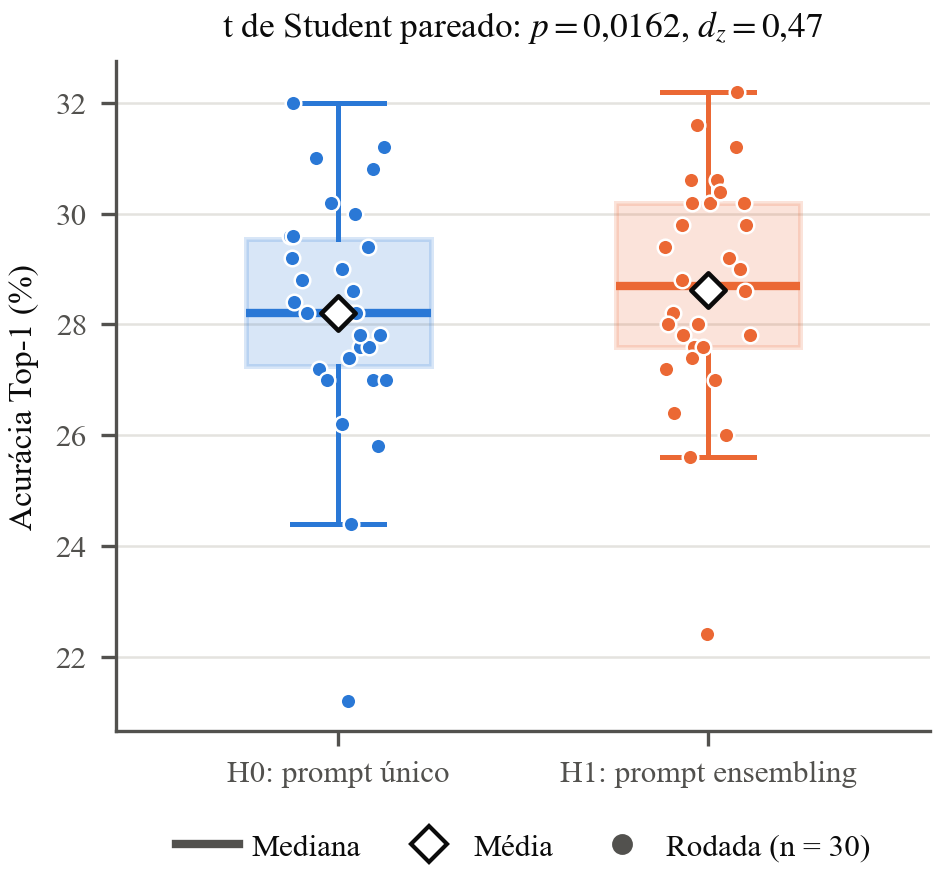

fig2_evolucao_pareada.png


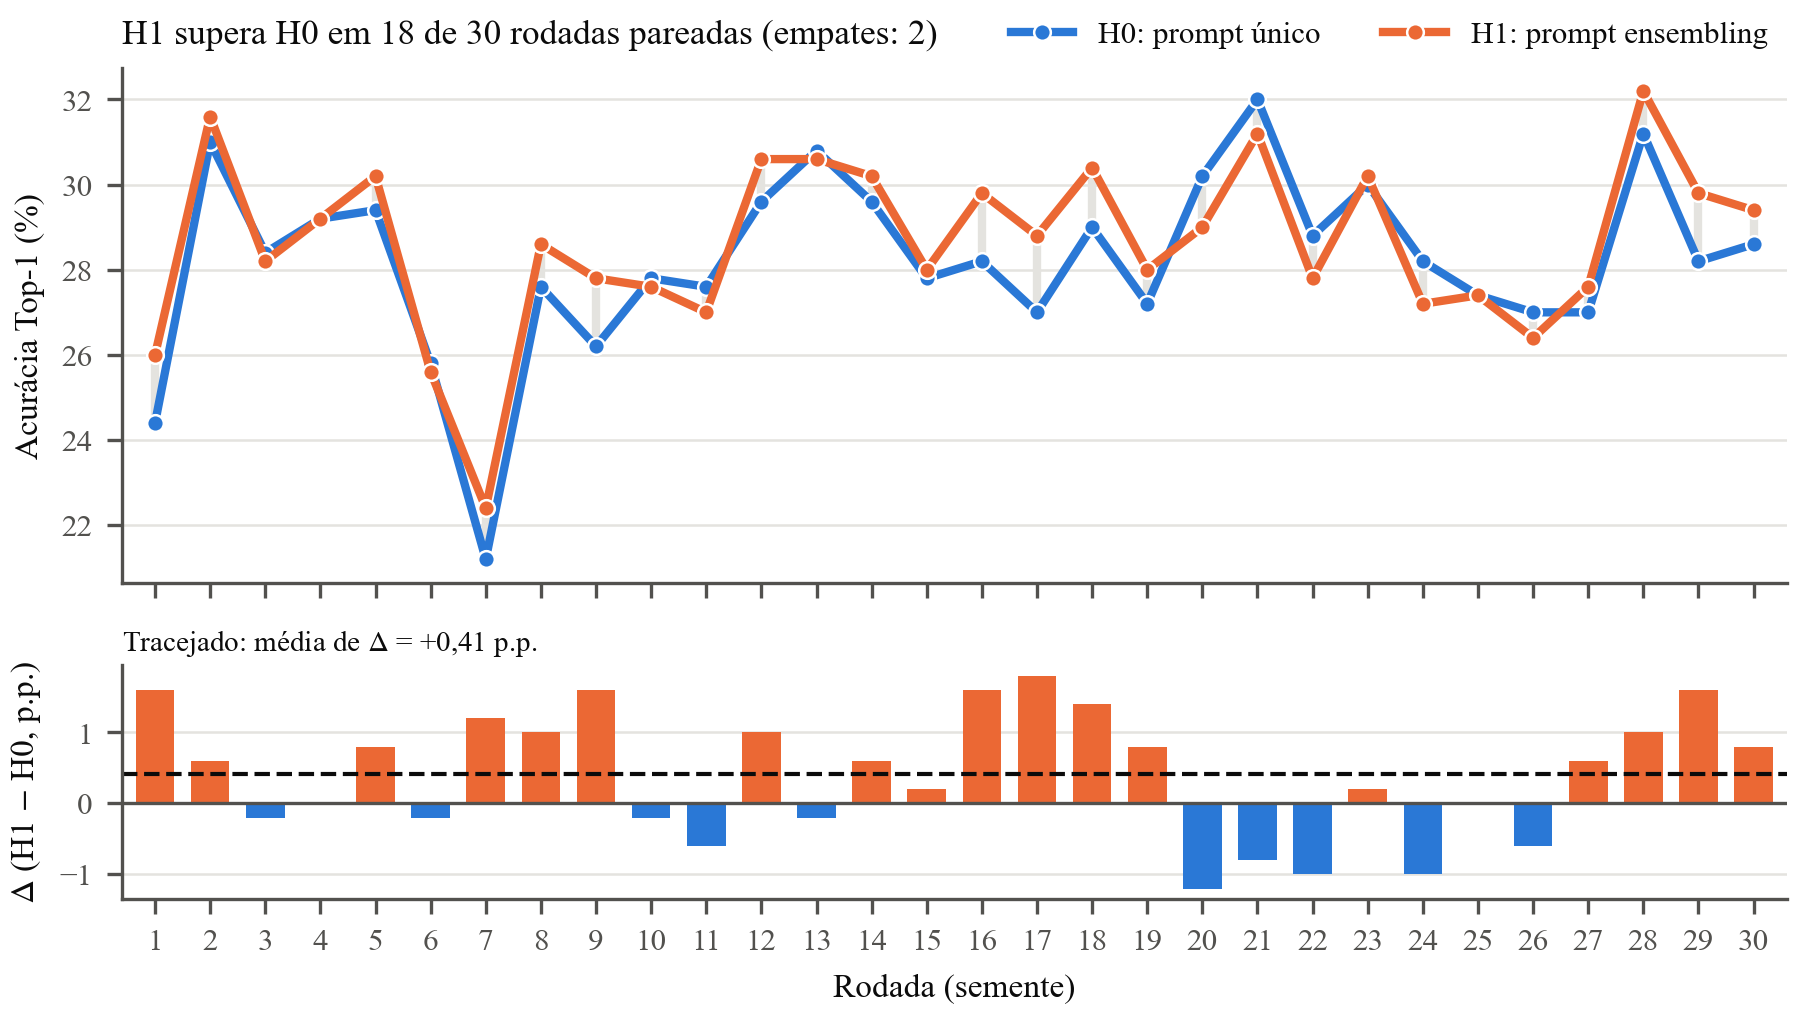

fig3_tradeoff_metricas.png


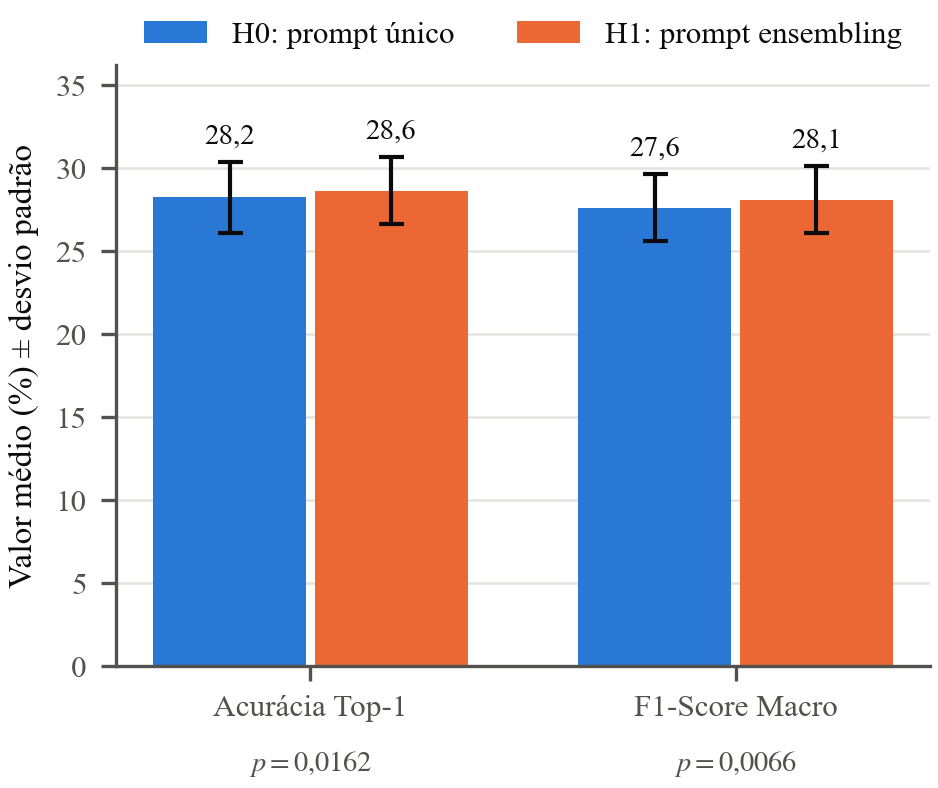

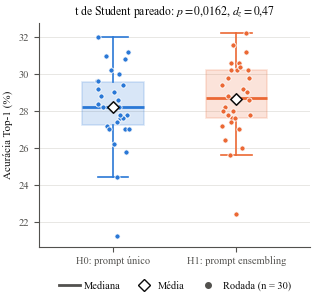

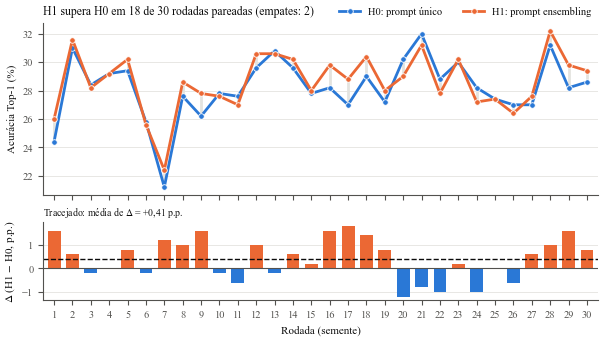

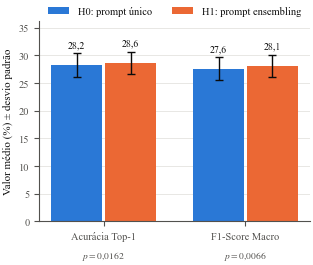

In [8]:
paths = [
    fig_accuracy_box(results, summary, config.FIGURES_DIR / "fig1_comparacao_acuracia.png"),
    fig_paired_evolution(results, summary, config.FIGURES_DIR / "fig2_evolucao_pareada.png"),
    fig_metric_bars(summary, config.FIGURES_DIR / "fig3_tradeoff_metricas.png"),
]
for path in paths:
    print(path.name)
    display(Image(filename=path, width=640))

## 7. Conclusão do teste de hipótese

In [9]:
acc = summary["metricas"]["acuracia_top1"]
f1 = summary["metricas"]["f1_macro"]
delta = acc["diferenca_H1_menos_H0"]["media"] * 100
ci = [100 * v for v in acc["ic95_media_diferenca"]]
decision = "rejeitamos H0" if acc["rejeita_H0"] else "não rejeitamos H0"
print(f"Acurácia Top-1: H0 = {100 * acc['H0']['media']:.2f}% | H1 = {100 * acc['H1']['media']:.2f}%")
print(f"Diferença média = {delta:+.2f} p.p. (IC 95%: [{ci[0]:+.2f}; {ci[1]:+.2f}]) | H1 > H0 em {acc['rodadas_H1_maior']}/{acc['n_pares']} rodadas")
print(f"Shapiro-Wilk em Δ: W = {acc['shapiro_wilk']['W']:.4f}, p = {acc['shapiro_wilk']['p_valor']:.4f} -> {acc['teste']}")
print(f"Estatística = {acc['estatistica']:.4f}, p = {acc['p_valor']:.3e}, d_z = {acc['cohen_d_pareado']:.2f} -> {decision} (alpha = {config.ALPHA})")
print(f"F1 Macro: p = {f1['p_valor']:.3e}, d_z = {f1['cohen_d_pareado']:.2f}, rejeita H0 = {f1['rejeita_H0']}")

Acurácia Top-1: H0 = 28.21% | H1 = 28.63%
Diferença média = +0.41 p.p. (IC 95%: [+0.08; +0.74]) | H1 > H0 em 18/30 rodadas
Shapiro-Wilk em Δ: W = 0.9505, p = 0.1745 -> t de Student pareado
Estatística = 2.5535, p = 1.618e-02, d_z = 0.47 -> rejeitamos H0 (alpha = 0.05)
F1 Macro: p = 6.630e-03, d_z = 0.53, rejeita H0 = True
